The following runs inside the BenchMAX environment.

# Active multi-agent imitation learning in Gridworld

Compare behavioral cloning, MURMAIL, and MAIL-WARM on Gridworld 1, reproducing
Figure 2(b) of [arXiv:2510.09325](https://arxiv.org/abs/2510.09325)
([reference code](https://github.com/emanuelenevali/MAIL_WARM)).
BC learns from demonstrations; MURMAIL queries the expert interactively; MAIL-WARM
uses reward-free exploration before querying the expert. The algorithms and Nash
expert are defined below; BenchMAX supplies the game and evaluation.

## Setup

From the repository root, run `uv sync --extra training --group notebook`, then
`uv run jupyter lab`. Select that environment and run the cells in order.
The expert is computed locally; no external data or authentication is needed.

## Solve the tabular zero-sum game

Solve each matrix game by linear programming. With `with_policies=True`, return the value and both equilibrium strategies; otherwise return only the value.

In [ ]:
import numpy as np

_SADDLE_TOLERANCE = 1e-12


def solve_matrix_game(
    payoffs: np.ndarray, *, with_policies: bool = False
) -> float | tuple[float, np.ndarray, np.ndarray]:
    payoffs = np.asarray(payoffs, dtype=float)

    if not with_policies:
        maximin = payoffs.min(axis=1).max()
        minimax = payoffs.max(axis=0).min()
        if minimax - maximin <= _SADDLE_TOLERANCE:
            return float(maximin)

    # Shifting the matrix strictly positive keeps the value away from the free
    # variable's sign change without altering the equilibrium.
    shift = payoffs.min() - 1.0
    shifted = payoffs - shift

    value = solve_half(shifted, maximize=True)

    if not with_policies:
        return float(value[0] + shift)

    column_value = solve_half(shifted, maximize=False)
    return float(value[0] + shift), value[1:], column_value[1:]

### Linear program for one player

In [ ]:
from scipy.optimize import linprog


def solve_half(shifted: np.ndarray, *, maximize: bool) -> np.ndarray:
    rows, columns = shifted.shape

    if maximize:
        size, constraints, matrix = rows, columns, -shifted.T
        objective = -1.0
    else:
        size, constraints, matrix = columns, rows, shifted
        objective = 1.0

    cost = np.zeros(size + 1)
    cost[0] = objective
    inequality = np.hstack([np.full((constraints, 1), 1.0 if maximize else -1.0), matrix])
    equality = np.hstack([np.zeros((1, 1)), np.ones((1, size))])

    result = linprog(
        cost, A_ub=inequality, b_ub=np.zeros(constraints), A_eq=equality, b_eq=np.ones(1),
        bounds=[(None, None)] + [(0.0, 1.0)] * size, method="highs"
    )
    if not result.success:
        raise RuntimeError(f"matrix game linear program failed: {result.message}")

    return result.x

### Nash value iteration

Apply minimax updates until the state values converge, then recover both policies. Multiple equilibria can exist, so solver tie-breaking can change the selected strategies.

In [ ]:
def nash_value_iteration(
    transitions: np.ndarray, payoffs: np.ndarray, discount: float, *, tolerance: float = 1e-6,
    max_iterations: int = 1000
) -> tuple[np.ndarray, np.ndarray, np.ndarray, int]:
    num_states, num_row_actions, num_column_actions, _ = transitions.shape
    flat = transitions.reshape(-1, num_states)

    values = np.zeros(num_states)
    iterations = max_iterations

    for sweep in range(max_iterations):
        stage = payoffs + discount * flat.dot(values).reshape(num_states, num_row_actions, num_column_actions)
        maximin = stage.min(axis=2).max(axis=1)
        minimax = stage.max(axis=1).min(axis=1)
        pure = minimax - maximin <= _SADDLE_TOLERANCE

        updated = np.where(pure, maximin, 0.0)

        for state in np.flatnonzero(~pure):
            updated[state] = solve_matrix_game(stage[state])

        change = np.max(np.abs(updated - values))
        values = updated

        if change < tolerance:
            iterations = sweep + 1
            break

    stage = payoffs + discount * flat.dot(values).reshape(num_states, num_row_actions, num_column_actions)
    policy_0 = np.zeros((num_states, num_row_actions))
    policy_1 = np.zeros((num_states, num_column_actions))

    for state in range(num_states):
        _, row, column = solve_matrix_game(stage[state], with_policies=True)
        policy_0[state] = row
        policy_1[state] = column

    return values, policy_0, policy_1, iterations

### Pin expert actions

`pinned` maps each player to `{state: action}` choices. Unspecified states use the computed equilibrium.

In [ ]:
from collections.abc import Mapping

from benchmax.games.tabular import TabularZeroSumMarkovGame
from benchmax.types import Action, Player


def nash_equilibrium_expert(
    game: TabularZeroSumMarkovGame, pinned: Mapping[Player, Mapping[int, Action]] | None = None
) -> dict[Player, np.ndarray]:
    if game.discount is None:
        raise ValueError(f"{game.name!r} declares no discount factor")

    pinned = pinned or {}

    for player, choices in pinned.items():
        if player not in game.players:
            raise ValueError(f"pinned player {player!r} is not one of {game.players!r}")

        for state, action in choices.items():
            if not 0 <= state < game.num_states:
                raise ValueError(f"pinned state {state} is outside {game.name!r}'s " f"{game.num_states} states")

            if action not in game.action_spaces[player]:
                raise ValueError(f"pinned action {action} is not legal for player {player}")

    _, solved_0, solved_1, _ = nash_value_iteration(game.transitions, game.payoffs, game.discount)

    solved = {0: solved_0, 1: solved_1}
    policies = {player: np.zeros_like(solved[player]) for player in game.players}

    for player, choices in pinned.items():
        for state, action in choices.items():
            policies[player][state, action] = 1.0

    for player, strategy in policies.items():
        unpinned = strategy.sum(axis=1) == 0.0
        strategy[unpinned] = solved[player][unpinned]

    return policies

## Select the Gridworld expert

Pin the expert to the pure Nash path used in Gridworld 1.

In [1]:
import numpy as np

from benchmax.games.tabular import Gridworld

MOVE_INDEX = {"left": 0, "right": 1, "up": 2, "down": 3}

#: The pure Nash path of Gridworld 1: the ``(row, column)`` positions of both
#: players along it, with the move each makes there. ``None`` leaves that
#: player's action at that state to the solver.
PURE_NASH_PATH: tuple[tuple[tuple[int, int], tuple[int, int], str, str], ...] = (
    ((1, 0), (2, 1), "right", "right"),
    ((1, 1), (2, 2), "right", None),
    ((0, 0), (1, 1), None, "right"),
    ((0, 1), (1, 2), "right", "up"),
    ((0, 0), (2, 2), "right", "up"),
)


def gridworld_1_expert(game: Gridworld) -> dict[int, np.ndarray]:
    pinned: dict[int, dict[int, int]] = {0: {}, 1: {}}

    for first, second, move_0, move_1 in PURE_NASH_PATH:
        state = game.state_index_of(first, second)

        for player, move in ((0, move_0), (1, move_1)):
            if move is not None:
                pinned[player][state] = MOVE_INDEX[move]

    return nash_equilibrium_expert(game, pinned)

## Define BC, MURMAIL, and MAIL-WARM

The helpers sample actions and normalize counts, leaving unseen states uniform. To match the reference, induced transitions contract the second action axis with the supplied strategy.

In [ ]:
from typing import TypeAlias

import numpy as np

from benchmax.games.tabular import TabularZeroSumMarkovGame

#: One row-stochastic ``(states, actions)`` strategy per player.
Profile: TypeAlias = dict[int, np.ndarray]


def sample_actions(strategies: np.ndarray, states: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    cumulative = np.cumsum(strategies[states], axis=1)
    draws = rng.random((len(states), 1))
    return (draws >= cumulative).sum(axis=1)


def strategy_from_counts(counts: np.ndarray) -> np.ndarray:
    totals = counts.sum(axis=1, keepdims=True)
    uniform = np.full_like(counts, 1.0 / counts.shape[1])
    return np.divide(counts, totals, out=uniform, where=totals > 0)


def induced_transitions(game: TabularZeroSumMarkovGame, strategy: np.ndarray) -> np.ndarray:
    return np.einsum("sabt,sb->sat", game.transitions, strategy)

### Behavioral cloning

Collect the largest demonstration dataset once, with geometrically distributed trajectory lengths, then fit policies from growing prefixes.

In [ ]:
from collections.abc import Sequence


def behavior_cloning(
    game: TabularZeroSumMarkovGame, expert: Profile, dataset_sizes: Sequence[int], rng: np.random.Generator
) -> list[Profile]:
    counts = {player: np.zeros_like(expert[player], dtype=float) for player in game.players}
    total = max(dataset_sizes, default=0)
    if total == 0:
        return [{p: strategy_from_counts(counts[p]) for p in game.players} for _ in dataset_sizes]

    seed = int(rng.integers(2**31))
    boundaries = np.flatnonzero(rng.random(total - 1) < 1.0 - game.discount) + 1
    horizons = np.diff(np.r_[0, boundaries, total])
    _, data = game.rollout(
        game.tabular_profile(expert), episodes=len(horizons), seed=seed, max_steps=horizons, collect_data=True
    )
    # Batched rollout interleaves episodes; identify each row's position in the trajectory sequence.
    starts = np.r_[0, boundaries]
    samples = {
        player: (game.state_indices(rows["observations"]), rows["actions"],
                 starts[rows["episode_ids"]] + rows["step_ids"])
        for player, rows in data.items()
    }
    learned, previous = [], 0
    for target in dataset_sizes:
        for player, (states, actions, positions) in samples.items():
            selected = (positions >= previous) & (positions < target)
            np.add.at(counts[player], (states[selected], actions[selected]), 1)

        learned.append({player: strategy_from_counts(counts[player]) for player in game.players})
        previous = target

    return learned

### MURMAIL: optimistic planning

Use UCBVI to plan an optimistic response in the induced MDP.

In [ ]:
def optimistic_plan(
    transitions: np.ndarray, rewards: np.ndarray, discount: float, initial_state_distribution: np.ndarray,
    rng: np.random.Generator, horizon: int, episodes: int
) -> np.ndarray:
    num_states, num_actions, _ = transitions.shape
    visits = np.zeros((num_states, num_actions))
    successors = np.zeros((num_states, num_actions, num_states))
    returns = np.zeros((num_states, num_actions))
    values = np.zeros(num_states)
    steps = 0

    for _ in range(episodes):
        stabilizer = 1e-10
        model = successors / (visits[..., None] + stabilizer)
        mean_reward = returns / (visits + stabilizer)
        bonus = np.sqrt(np.log(max(1, steps + 1)) / (visits + stabilizer))
        optimistic = mean_reward + bonus

        for _ in range(horizon):
            values = np.max(optimistic + discount * (model @ values), axis=1)

        greedy = np.argmax(optimistic + discount * (model @ values), axis=1)

        state = rng.choice(num_states, p=initial_state_distribution)

        for _ in range(horizon):
            action = greedy[state]
            successor = rng.choice(num_states, p=transitions[state, action])
            visits[state, action] += 1
            successors[state, action, successor] += 1
            returns[state, action] += rewards[state]
            state = successor
            steps += 1

    final = np.zeros(num_states)

    for _ in range(2 * horizon):
        final = np.max(mean_reward + discount * (model @ final), axis=1)

    policy = np.zeros((num_states, num_actions))
    policy[np.arange(num_states), np.argmax(mean_reward + discount * (model @ final), axis=1)] = 1.0
    return policy

### MURMAIL: agreement and occupancy

Estimate disagreement with the expert and compute discounted state visitation for choosing query states.

In [ ]:
def agreement_reward(expert: np.ndarray, strategy: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    states = np.arange(len(strategy))
    first = sample_actions(expert, states, rng)
    second = sample_actions(expert, states, rng)
    return ((first == second).astype(float) - 2.0 * strategy[states, first] + np.sum(strategy**2, axis=1))


def occupancy(game: TabularZeroSumMarkovGame, strategy_0: np.ndarray, strategy_1: np.ndarray) -> np.ndarray:
    weights = strategy_0[:, :, None] * strategy_1[:, None, :]
    chain = (game.transitions * weights[:, :, :, None]).sum(axis=(1, 2))
    occupancy = np.linalg.solve(
        np.eye(game.num_states) - game.discount * chain.T, (1.0 - game.discount) * game.initial_state_distribution
    )
    return occupancy / occupancy.sum()

### MURMAIL: query and update

Plan a response, query the expert at one state, and update the strategy by mirror descent. `query_states="uniform"` matches the reference implementation; `"occupancy"` follows the stated method.

In [ ]:
def murmail(
    game: TabularZeroSumMarkovGame, expert: Profile, query_counts: Sequence[int], rng: np.random.Generator,
    learning_rate: float = 50.0, horizon: int = 10, episodes: int = 10, query_states: str = "occupancy"
) -> list[Profile]:
    strategies = {player: np.full((game.num_states, 4), 0.25) for player in game.players}
    averaged = {player: strategies[player].copy() for player in game.players}
    targets = sorted(query_counts)
    recorded: list[Profile] = []
    reached = 0

    for iteration in range(targets[-1]):
        for player in game.players:
            response = optimistic_plan(
                induced_transitions(game, strategies[player]),
                agreement_reward(expert[player], strategies[player], rng), game.discount,
                game.initial_state_distribution, rng, horizon, episodes
            )

            if query_states == "uniform":
                # What the reference samples in practice: its occupancy helper
                # computes (I - gP)^-1 @ 1, which equals 1/(1-g) at every state
                # for any stochastic P, so the strategies and the initial
                # distribution both cancel and the draw is flat.
                distribution = np.full(game.num_states, 1.0 / game.num_states)
            elif player == 0:
                distribution = occupancy(game, strategies[0], response)
            else:
                distribution = occupancy(game, response, strategies[1])

            state = rng.choice(game.num_states, p=distribution)
            action = int(sample_actions(expert[player], np.asarray([state]), rng)[0])
            gradient = strategies[player][state, action] - 1.0
            updated = strategies[player].copy()
            updated[state, action] *= np.exp(-learning_rate * gradient)
            updated[state] /= updated[state].sum()
            strategies[player] = updated

        for player in game.players:
            averaged[player] = (iteration * averaged[player] + strategies[player]) / (iteration + 1)

        while reached < len(targets) and targets[reached] == iteration + 1:
            recorded.append({player: averaged[player].copy() for player in game.players})
            reached += 1

    return recorded

### MAIL-WARM: learn state-seeking policies

Learn one policy per target state with tabular Q-learning. Limited training leaves some states unexplored, which helps diversify the later trajectories.

In [ ]:
def seeking_policies(
    transitions: np.ndarray, initial_state_distribution: np.ndarray, rng: np.random.Generator, horizon: int,
    episodes: int = 200, learning_rate: float = 0.1, exploration: float = 0.2, discount: float = 0.99
) -> np.ndarray:
    num_states, num_actions, _ = transitions.shape
    cumulative = np.cumsum(transitions, axis=2)
    starts = np.cumsum(initial_state_distribution)
    policies = np.empty((num_states, num_states, num_actions))

    for target in range(num_states):
        values = np.zeros((num_states, num_actions))

        for _ in range(episodes):
            state = int(np.searchsorted(starts, rng.random()))

            for _ in range(horizon):
                if rng.random() < exploration:
                    action = int(rng.integers(num_actions))
                else:
                    action = int(np.argmax(values[state]))

                successor = int(np.searchsorted(cumulative[state, action], rng.random()))
                target_value = float(successor == target) + discount * values[successor].max()
                values[state, action] += learning_rate * (target_value - values[state, action])
                state = successor

        policy = np.zeros((num_states, num_actions))
        policy[np.arange(num_states), np.argmax(values, axis=1)] = 1.0
        policy[np.all(values == 0.0, axis=1)] = 1.0 / num_actions
        policy[target] = 1.0 / num_actions
        policies[target] = policy

    return policies

### MAIL-WARM: collect visited states

Sample trajectories using randomly chosen state-seeking policies.

In [ ]:
def explore(
    transitions: np.ndarray, policies: np.ndarray, trajectories: int, horizon: int,
    initial_state_distribution: np.ndarray, rng: np.random.Generator
) -> np.ndarray:
    num_states = len(transitions)
    cumulative = np.cumsum(transitions, axis=2)
    starts = np.cumsum(initial_state_distribution)
    by_policy = np.cumsum(policies, axis=2)

    visited = np.empty(trajectories * horizon, dtype=int)
    position = 0

    for _ in range(trajectories):
        policy = by_policy[rng.integers(num_states)]
        state = int(np.searchsorted(starts, rng.random()))

        for _ in range(horizon):
            visited[position] = state
            position += 1
            action = int(np.searchsorted(policy[state], rng.random()))
            state = int(np.searchsorted(cumulative[state, action], rng.random()))

    return visited

### MAIL-WARM: fit policies from expert queries

Query the expert at states reached during exploration, then fit action frequencies at each sampling budget.

In [ ]:
def mail_warm(
    game: TabularZeroSumMarkovGame, expert: Profile, sample_sizes: Sequence[int], rng: np.random.Generator,
    horizon: int = 10
) -> list[Profile]:
    induced = {player: induced_transitions(game, expert[player]) for player in game.players}
    seeking = {
        player: seeking_policies(
            induced[player], game.initial_state_distribution, rng, horizon
        )
        for player in game.players
    }

    learned = []

    for trajectories in sample_sizes:
        strategies = {}

        for player in game.players:
            states = explore(
                induced[player], seeking[player], trajectories, horizon, game.initial_state_distribution, rng
            )
            actions = sample_actions(expert[player], states, rng)
            counts = np.zeros((game.num_states, 4))
            np.add.at(counts, (states, actions), 1.0)
            strategies[player] = strategy_from_counts(counts)

        learned.append(strategies)

    return learned

## The game

3x3 grid, 72 states, 4 actions, two players moving at once. The goal is
absorbing and pays every step, so episodes never end and the objective is
discounted return.

In [2]:
from benchmax import load_game

# The experiment's layout, stated here rather than taken from the entry's
# defaults: the goal in the top-right corner, and both players starting three
# steps from it, which is what makes the Nash value zero.
game = load_game("gridworld_3x3", params={"goal": [0, 2], "initial_state": [[1, 0], [2, 1]], "discount": 0.9,})
game

## The expert

Compute the imitation expert policy: a Nash equilibrium, pinned to the pure path
Gridworld 1 uses. Its Nash gap should be 0.

In [3]:
expert = gridworld_1_expert(game)

# The algorithms keep their natural strategy tables. The game supplies the
# conversion to BenchMAX's shared policy interface.
game.evaluate(game.tabular_profile(expert))

{'player_improvements': {0: 0.0, 1: 0.0},
 'nash_gap': 0.0,
 'nash_conv': 0.0,
 'expected_returns': {0: 0.0, 1: -0.0},
 'exploitability': 0.0}

## What each algorithm needs

- **BC** samples only, through `game.rollout()`, collecting the largest dataset once with geometric horizons and evaluating its prefixes, as in the original implementation. Checkpoints do not reset trajectories. Rollout now owns action/environment seeds, so individual seeded samples differ from the original demo.
- **MURMAIL** and **MAIL-WARM** plan in induced MDPs, so they read
  `game.transitions`.

## Run

10 seeds. The algorithms return strategy tables; the game converts them to
the shared policy interface and evaluates them.
MURMAIL runs to 5,000 queries; the published curve used 10,000.

In [4]:
import numpy as np

SEEDS = 10
# One grid for all three, so the curves are sampled at the same budgets. The
# unit differs per algorithm: demonstrations for BC and MAIL-WARM, interactive
# expert queries for MURMAIL.
BUDGETS = [10, 20, 50, 100, 200, 500, 1000, 2000, 5000]


def nash_gaps(strategy_tables):
    return [game.evaluate(game.tabular_profile(tables))["nash_gap"] for tables in strategy_tables]


runs = {"bc": [], "murmail": [], "mail_warm": []}

for seed in range(SEEDS):
    runs["bc"].append(nash_gaps(behavior_cloning(game, expert, BUDGETS, np.random.default_rng(seed))))
    runs["mail_warm"].append(nash_gaps(mail_warm(game, expert, BUDGETS, np.random.default_rng(seed))))
    runs["murmail"].append(
        nash_gaps(
            murmail(
                game,
                expert,
                BUDGETS,
                np.random.default_rng(seed),
                # The reference draws its query state uniformly, not from the
                # discounted occupancy the method specifies: its helper computes
                # a quantity that is constant for any stochastic transition
                # matrix. Reproducing its curve means reproducing that.
                query_states="uniform",
            )
        )
    )

summary = {
    name: (
        np.asarray(BUDGETS, dtype=float),
        np.mean(np.asarray(values), axis=0),
        np.std(np.asarray(values), axis=0),
    )
    for name, values in runs.items()
}
for name, (_, mean, _) in summary.items():
    print(f"{name:10s} {[f'{v:.3f}' for v in mean]}")

bc         ['8.035', '8.035', '8.035', '8.035', '8.035', '8.035', '8.035', '8.035', '8.035']
murmail    ['8.244', '8.352', '8.487', '8.456', '8.099', '6.346', '4.607', '3.126', '1.619']
mail_warm  ['4.394', '1.885', '1.348', '0.393', '0.342', '0.000', '0.000', '0.000', '0.000']


## Compare imitation methods

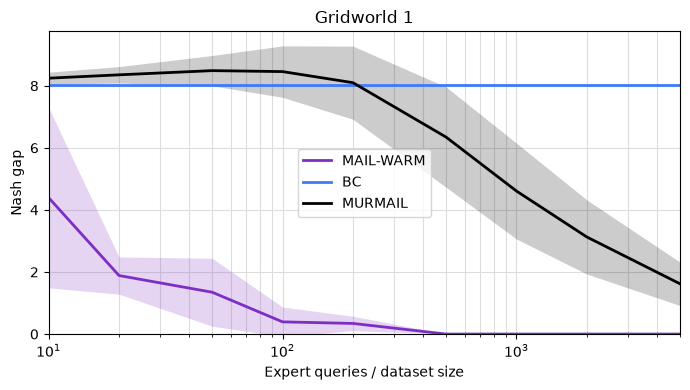

In [5]:
import matplotlib.pyplot as plt

COLORS = {"mail_warm": "#7d2ec4", "bc": "#3d7bfb", "murmail": "#000000"}
LABELS = {"mail_warm": "MAIL-WARM", "bc": "BC", "murmail": "MURMAIL"}

figure, axis = plt.subplots(figsize=(7.0, 4.0))
for name in ("mail_warm", "bc", "murmail"):
    x, mean, deviation = summary[name]
    axis.plot(x, mean, color=COLORS[name], linewidth=2.0, label=LABELS[name])
    axis.fill_between(x, mean - deviation, mean + deviation, color=COLORS[name], alpha=0.2, linewidth=0)

axis.set_xscale("log")
axis.set_xlim(min(BUDGETS), max(BUDGETS))
axis.set_ylim(bottom=0.0)
axis.set_xlabel("Expert queries / dataset size")
axis.set_ylabel("Nash gap")
axis.set_title("Gridworld 1")
axis.grid(True, which="both", color="#dddddd", linewidth=0.8)
axis.set_axisbelow(True)
axis.legend()
figure.tight_layout()

The results qualitatively reproduce the published trends. Implementation differences and bug fixes mean the numerical values may differ from the reference.